# Redes Neurais Artificiais — Projeto Prático 2.1

- Redes Neurais Artificiais 2026.2
- Profa. Elloá B. Guedes (ebgcosta@uea.edu.br)
- http://github.com/elloa

### Equipe

- João Victor Mattos Lopes (github.com/Jaum36) - 2315080034
- Gabriel Augusto da Eira Corrêa Benayon (github.com/devgabrielbenayon) - 2415310049

Identificador dos exemplos: (4 + 9) % 4 = 1. 

In [10]:
# Numpy obrigatório para manipulação de arrays e matrizes
import numpy as np

import matplotlib.pyplot as plt
import random 
import math
import pandas as pd
import prettytable as pt

# Só usar pra cálculo de métrica de desempenho
# import sklearn


In [11]:
identificador = (4 + 9) % 4

dados = np.load(f"data/data{identificador}20262.txt").reshape(-1, 3)
X = dados[:, :2]
y = dados[:, 2]

# Parte I - Resolvendo um Problema Linearmente Separável

In [12]:
class Perceptron:
  def __init__(self, taxa_aprendizado=0.1, intervalo_pesos=(-0.5, 0.5)):
    self.taxa_aprendizado = taxa_aprendizado
    self.intervalo_pesos = intervalo_pesos
    self.w = None  # [viés, w1, w2]

  def _adicionar_bias(self, X):
    return np.hstack((np.ones((X.shape[0], 1)), X))

  def _degrau(self, u):
    return np.where(u >= 0, 1, 0)

  def train(self, X, y, max_epocas=None, embaralhar=False, verbose=True):
    Xb = self._adicionar_bias(X)
    self.w = np.random.uniform(self.intervalo_pesos[0], self.intervalo_pesos[1], Xb.shape[1])

    if verbose:
      print(f"Vetor inicial de pesos [viés, w1, w2]: {self.w}")

    epocas = 0
    ajustes = 0

    # Sem max_epocas, treina até a convergência
    while max_epocas is None or epocas < max_epocas:
      epocas += 1
      erros = 0

      indices = np.random.permutation(len(Xb)) if embaralhar else np.arange(len(Xb))

      for i in indices:
        erro = y[i] - self._degrau(np.dot(self.w, Xb[i]))

        if erro != 0:
          self.w = self.w + self.taxa_aprendizado * erro * Xb[i]
          erros += 1
          ajustes += 1

      if erros == 0:
        break

    if verbose:
      print(f"Número total de ajustes no vetor de pesos: {ajustes}")
      print(f"Número de épocas até a convergência: {epocas}")

    return epocas, ajustes

  def predict(self, X):
    return self._degrau(np.dot(self._adicionar_bias(X), self.w))


In [13]:
dados = np.load("data/dataAll20262.txt").reshape(-1, 3)
entradas = dados[:, :2]
saida = dados[:, 2]

p = Perceptron(taxa_aprendizado=0.1, intervalo_pesos=(-0.5, 0.5))

epocas, ajustes = p.train(entradas, saida)

Vetor inicial de pesos [viés, w1, w2]: [ 0.12971751 -0.28982599  0.25275555]
Número total de ajustes no vetor de pesos: 65
Número de épocas até a convergência: 4


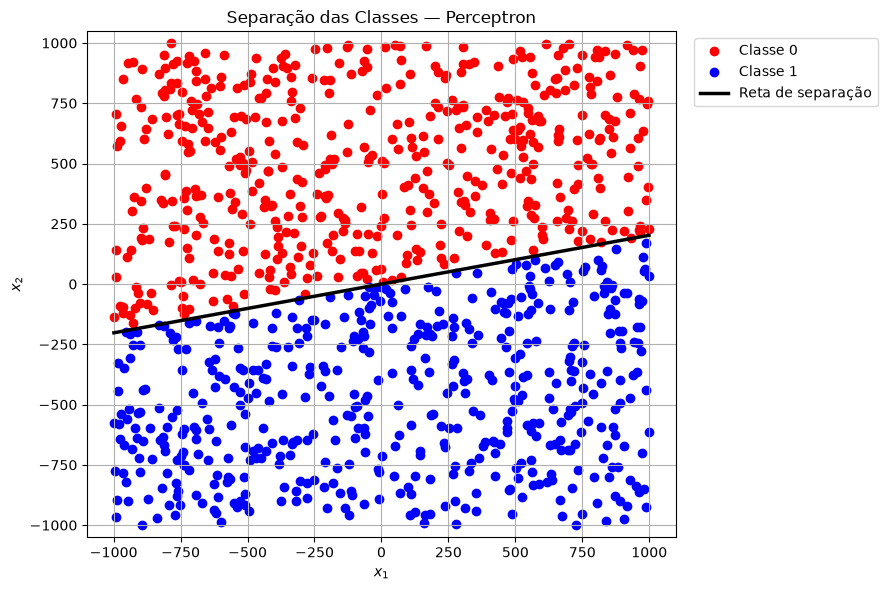

In [14]:
classe_0 = saida == 0
classe_1 = saida == 1

vies, w1, w2 = p.w

plt.figure(figsize=(9, 6))
plt.scatter(entradas[classe_0, 0], entradas[classe_0, 1], c='red', label="Classe 0")
plt.scatter(entradas[classe_1, 0], entradas[classe_1, 1], c='blue', label="Classe 1")

# Reta de separação: vies + w1*x1 + w2*x2 = 0
if w2 != 0:
  x1_reta = np.linspace(entradas[:, 0].min(), entradas[:, 0].max(), 200)
  x2_reta = -(w1 * x1_reta + vies) / w2
  plt.plot(x1_reta, x2_reta, color="black", linewidth=2.5, label="Reta de separação")
else:
  plt.axvline(-vies / w1, color="black", linewidth=2.5, label="Reta de separação")

plt.ylim(entradas[:, 1].min() - 50, entradas[:, 1].max() + 50)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Separação das Classes — Perceptron")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

# Parte II - Experimentação

Arquivo `data120262.txt` (identificador 1). O algoritmo da Parte I é executado 10 vezes para cada uma das 6 configurações de taxa de aprendizado η ∈ {0.4, 0.1, 0.01} e intervalo de inicialização dos pesos I ∈ {(−100, +100), (−0.5, +0.5)}.

In [15]:
taxas = [0.4, 0.1, 0.01]
intervalos = [(-100, 100), (-0.5, 0.5)]
repeticoes = 10

np.random.seed(identificador)

resultados = []

for taxa in taxas:
  for intervalo in intervalos:
    epocas_exec = np.zeros(repeticoes, dtype=int)
    ajustes_exec = np.zeros(repeticoes, dtype=int)

    for r in range(repeticoes):
      p2 = Perceptron(taxa_aprendizado=taxa, intervalo_pesos=intervalo)
      epocas_exec[r], ajustes_exec[r] = p2.train(X, y, verbose=False)

    resultados.append({
      "taxa": taxa,
      "intervalo_str": f"({intervalo[0]:+g}, {intervalo[1]:+g})",
      "epocas": epocas_exec,
      "ajustes": ajustes_exec,
    })
    print(f"η = {taxa}, I = {intervalo}: concluído")

η = 0.4, I = (-100, 100): concluído
η = 0.4, I = (-0.5, 0.5): concluído
η = 0.1, I = (-100, 100): concluído
η = 0.1, I = (-0.5, 0.5): concluído
η = 0.01, I = (-100, 100): concluído
η = 0.01, I = (-0.5, 0.5): concluído


In [16]:
tabela = pt.PrettyTable()
tabela.field_names = ["Taxa de Aprendizado", "Intervalo de Pesos", "Qtde Ajustes", "Min Épocas", "Max Épocas"]

for r in resultados:
  tabela.add_row([
    f"η = {r['taxa']}",
    r["intervalo_str"],
    f"{r['ajustes'].mean():.2f} ± {r['ajustes'].std(ddof=1):.2f}",
    r["epocas"].min(),
    r["epocas"].max(),
  ])

print(tabela)

+---------------------+--------------------+-----------------------+------------+------------+
| Taxa de Aprendizado | Intervalo de Pesos |      Qtde Ajustes     | Min Épocas | Max Épocas |
+---------------------+--------------------+-----------------------+------------+------------+
|       η = 0.4       |    (-100, +100)    | 317381.40 ± 132267.77 |    835     |    5169    |
|       η = 0.4       |    (-0.5, +0.5)    |  270723.30 ± 83558.92 |    1511    |    3643    |
|       η = 0.1       |    (-100, +100)    |  274658.70 ± 93979.51 |    1507    |    4581    |
|       η = 0.1       |    (-0.5, +0.5)    |  247757.80 ± 75504.20 |    737     |    2830    |
|       η = 0.01      |    (-100, +100)    | 360335.10 ± 140100.06 |    1683    |    6995    |
|       η = 0.01      |    (-0.5, +0.5)    | 294322.70 ± 136186.65 |    1486    |    7053    |
+---------------------+--------------------+-----------------------+------------+------------+


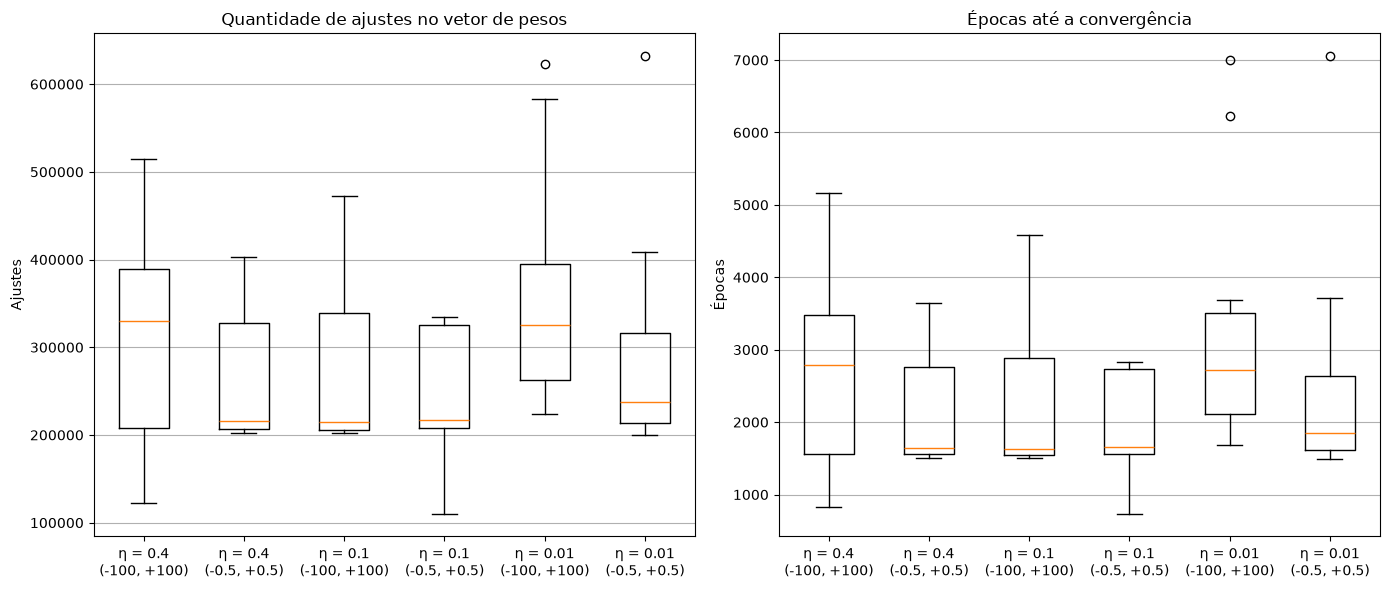

In [17]:
rotulos = [f"η = {r['taxa']}\n{r['intervalo_str']}" for r in resultados]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.boxplot([r["ajustes"] for r in resultados], tick_labels=rotulos)
ax1.set_title("Quantidade de ajustes no vetor de pesos")
ax1.set_ylabel("Ajustes")
ax1.grid(True, axis="y")

ax2.boxplot([r["epocas"] for r in resultados], tick_labels=rotulos)
ax2.set_title("Épocas até a convergência")
ax2.set_ylabel("Épocas")
ax2.grid(True, axis="y")

plt.tight_layout()
plt.show()

### Análise dos resultados

Não é possível afirmar que uma configuração seja melhor ou pior que as demais; os resultados indicam que elas são **equivalentes** para este conjunto de dados:

- **Sobreposição dos boxplots:** as caixas (intervalo interquartil) de todas as configurações se sobrepõem, tanto para a quantidade de ajustes quanto para o número de épocas. A variação *dentro* de cada configuração é maior do que a variação *entre* elas.
- **Médias próximas e alta dispersão:** as médias de ajustes ficam entre ≈ 248 mil (η = 0.1, (−0.5, +0.5)) e ≈ 360 mil (η = 0.01, (−100, +100)). Essa diferença, de ≈ 113 mil ajustes, é da mesma ordem dos desvios padrão observados (≈ 76 mil a ≈ 140 mil). As faixas de épocas também se sobrepõem: todas as configurações têm execuções convergindo entre ≈ 1.500 e ≈ 3.600 épocas.
- **Sem tendência consistente:** as configurações com pesos em (−100, +100) e η = 0.4 ou η = 0.01 tiveram medianas maiores (≈ 330 mil ajustes), mas com η = 0.1 o mesmo intervalo teve uma das menores medianas (≈ 215 mil). Não há, portanto, um efeito sistemático da taxa de aprendizado nem do intervalo de inicialização.

Esse comportamento é coerente com a teoria do Perceptron: quando os pesos iniciais são pequenos em relação aos passos de ajuste η·**x**, mudar η apenas reescala o vetor de pesos, sem alterar o sinal de **w**·**x**. Assim, a sequência de classificações e de ajustes tende a ser a mesma. O que mais influencia o resultado é a aleatoriedade da inicialização, e não a configuração escolhida.

Com apenas 10 repetições por configuração e a alta variância observada, uma afirmação mais forte exigiria mais execuções e um teste estatístico.

**Observação sobre o número elevado de épocas:** em `data120262.txt`, a reta de separação fica distante da origem (próxima de x₁ ≈ −300), o que exige um viés grande. A cada ajuste, o viés varia apenas η·1, enquanto w1 e w2 variam η·x, com |x| da ordem de 1000. Por isso o viés cresce devagar e o treinamento leva milhares de épocas em todas as configurações.